# Reamostragem com `imbalanced-learn`
Este notebook demonstra o uso prático e direto da biblioteca oficial `imbalanced-learn` (`imblearn`) para o tratamento de classes desbalanceadas. 

Ideal para aulas focadas em implementação ágil ou cenários reais de produção em Machine Learning, priorizando produtividade ao aplicar **Random Undersampling, Tomek Links, Random Oversampling e SMOTE**.

In [3]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from imblearn.over_sampling import RandomOverSampler, SMOTE
import numpy as np

# 1. Gerar o dataset desbalanceado (90% Maioria, 10% Minoria)
X, y = make_classification(n_samples=1000, n_features=2, n_redundant=0, 
                           n_clusters_per_class=1, weights=[0.90], 
                           flip_y=0.01, random_state=42)

print(f'Dataset gerado! Total: {len(y)} amostras (Maioria: {sum(y==0)}, Minoria: {sum(y==1)})')

Dataset gerado! Total: 1000 amostras (Maioria: 896, Minoria: 104)


## Aplicação das Técnicas e Visualização
Diferente da implementação manual do zero, a biblioteca `imblearn` unifica a sintaxe através do método `.fit_resample(X, y)`. O código abaixo inicializa todas as técnicas e plota o resultado comparativo.

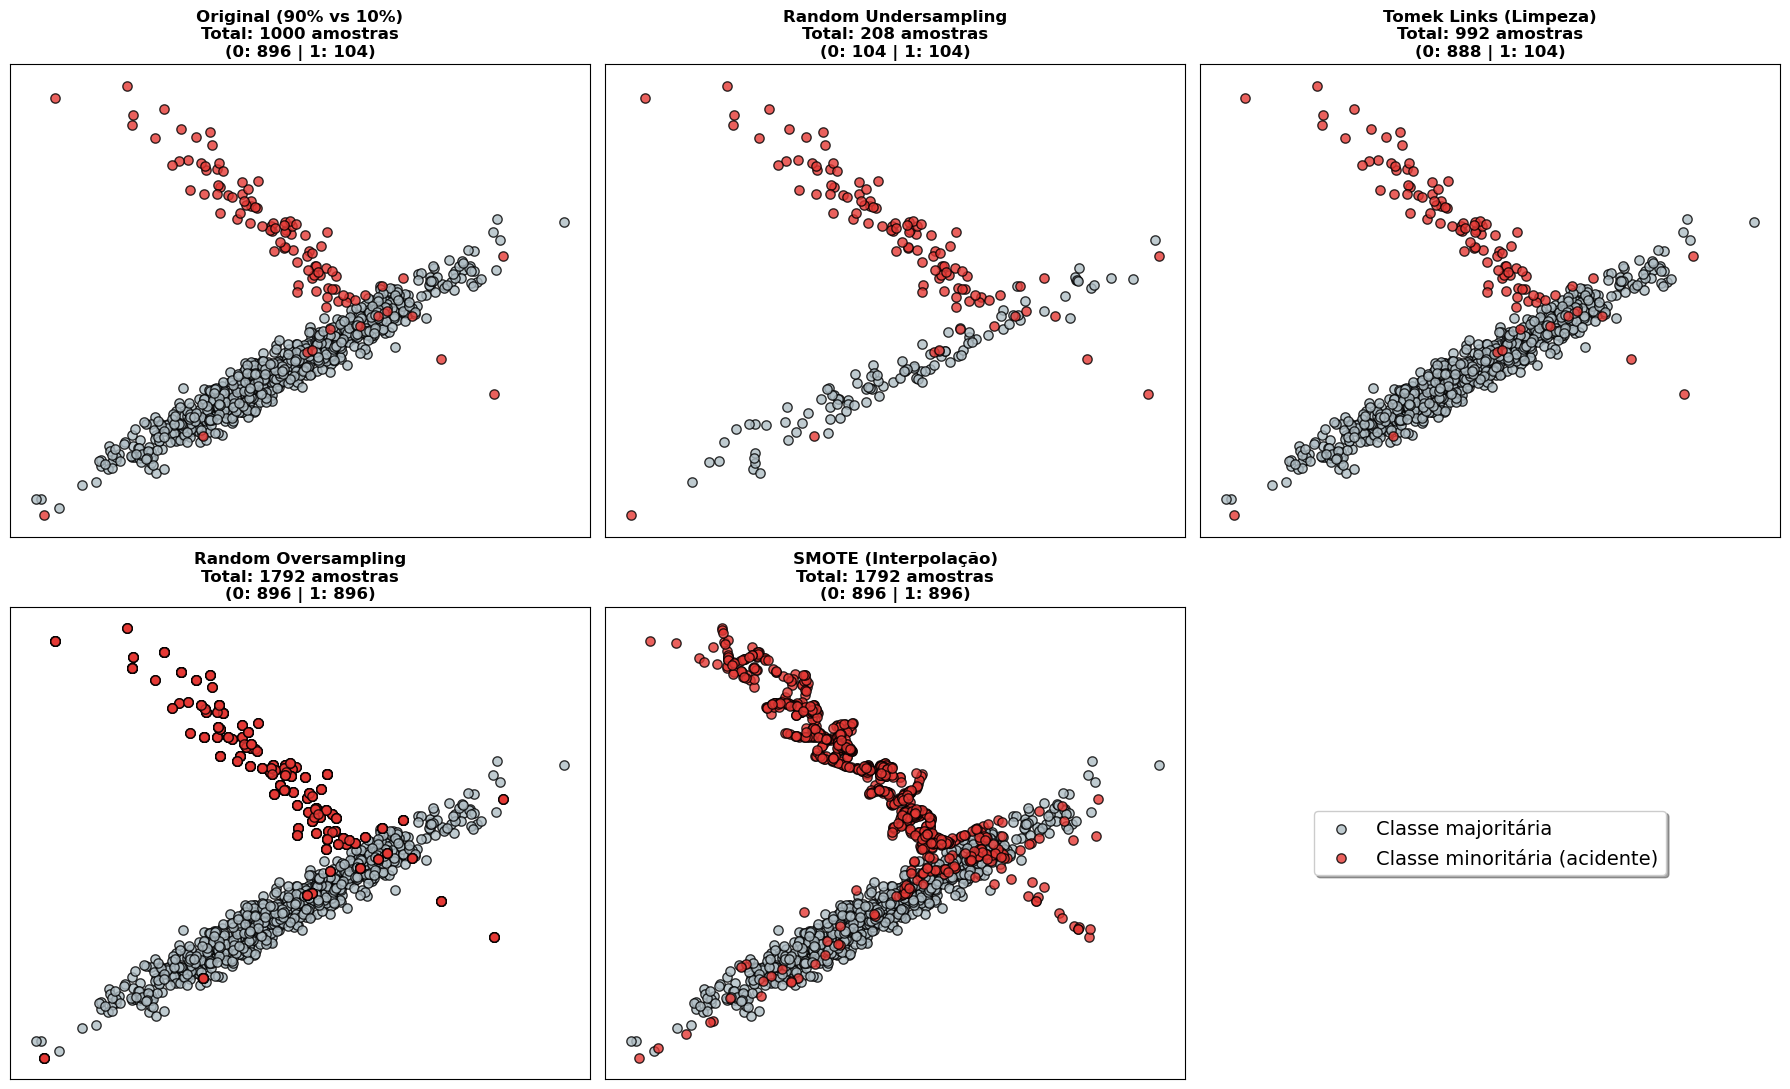

In [4]:
# 2. Inicializar os amostradores da biblioteca imbalanced-learn
samplers = {
    'Original (90% vs 10%)': None,
    'Random Undersampling': RandomUnderSampler(random_state=42),
    'Tomek Links (Limpeza)': TomekLinks(),
    'Random Oversampling': RandomOverSampler(random_state=42),
    'SMOTE (Interpolação)': SMOTE(random_state=42)
}

# 3. Configurar a figura do Matplotlib
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

colors = {0: '#B0BEC5', 1: '#E53935'}
labels = {0: 'Classe majoritária', 1: 'Classe minoritária (acidente)'}

for i, (title, sampler) in enumerate(samplers.items()):
    ax = axes[i]
    
    # Aplicar a reamostragem de forma direta
    if sampler is None:
        X_res, y_res = X, y
    else:
        X_res, y_res = sampler.fit_resample(X, y)
        
    # Plotar os pontos
    for class_val in [0, 1]:
        mask = y_res == class_val
        z_ord = 2 if class_val == 1 else 1 # Garante que a minoria fique visualmente por cima
        ax.scatter(X_res[mask, 0], X_res[mask, 1], 
                   c=colors[class_val], label=labels[class_val], 
                   alpha=0.8, edgecolor='k', s=45, zorder=z_ord)
        
    ax.set_title(f"{title}\nTotal: {len(y_res)} amostras\n(0: {sum(y_res==0)} | 1: {sum(y_res==1)})", 
                 fontsize=12, fontweight='bold')
    
    ax.grid(True, linestyle='--', alpha=0.3, zorder=0)
    ax.set_xticks([])
    ax.set_yticks([])

# Limpar o 6º plot que sobrou
axes[5].axis('off')

# Adicionar uma legenda global
handles, legend_labels = axes[0].get_legend_handles_labels()
axes[5].legend(handles, legend_labels, loc='center', fontsize=14, frameon=True, shadow=True)

plt.tight_layout()
plt.show()
